In [1]:
import os
import sys
import importlib
import pandas as pd
import matplotlib.pyplot as plt

project_root = os.path.abspath("..")
preprocessing_dir = os.path.join(
    project_root,
    "preprocessing"
)

if preprocessing_dir not in sys.path:
    sys.path.insert(0, preprocessing_dir)

import dataset_loader
importlib.reload(dataset_loader)

print("Dataset loader imported successfully!")

Dataset loader imported successfully!


In [2]:
csv_path = "D:\\AI-Powered-Diabetic-Retinopathy-System\\ml-model\\dataset\\raw\\train.csv"

df = dataset_loader.load_metadata(csv_path)

print("Dataset shape:", df.shape)

Dataset shape: (3662, 2)


In [3]:
image_dir = "D:\\AI-Powered-Diabetic-Retinopathy-System\\ml-model\\dataset\\raw\\train_images"

df = dataset_loader.create_image_paths(
    df,
    image_dir
)

df = dataset_loader.validate_image_paths(df)

train_df, validation_df, test_df = (
    dataset_loader.split_dataset(df)
)

In [ ]:
class_counts = (
    train_df["diagnosis"]
    .value_counts()
    .sort_index()
)

print(class_counts)

diagnosis
0    1263
1     259
2     699
3     135
4     207
Name: count, dtype: int64


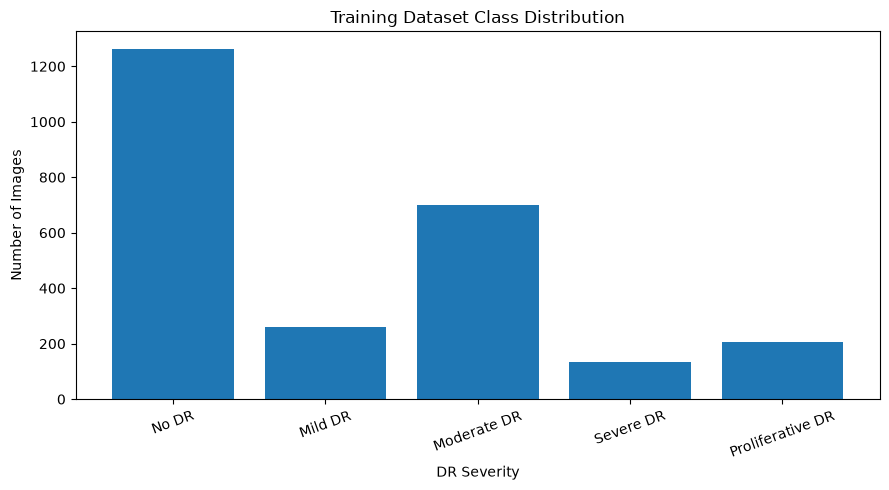

In [5]:
class_names = [
    "No DR",
    "Mild DR",
    "Moderate DR",
    "Severe DR",
    "Proliferative DR"
]

plt.figure(figsize=(9, 5))

plt.bar(
    class_names,
    class_counts.values
)

plt.xlabel("DR Severity")
plt.ylabel("Number of Images")
plt.title("Training Dataset Class Distribution")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [6]:
import class_weights
importlib.reload(class_weights)

<module 'class_weights' from 'd:\\AI-Powered-Diabetic-Retinopathy-System\\ml-model\\preprocessing\\class_weights.py'>

In [7]:
weights = class_weights.calculate_class_weights(
    train_df["diagnosis"].values
)

print(weights)

{0: 0.4058590657165479, 1: 1.9791505791505792, 2: 0.7333333333333333, 3: 3.797037037037037, 4: 2.476328502415459}
